Ejemplo Aplicativo de Interpretabilidad Intrínseca en Python
Voy a mostrarte un ejemplo completo con un modelo interpretable por diseño (árbol de decisión) y cómo analizar sus componentes directamente.

In [9]:
# 1. Preparación del Entorno y Datos
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Cargar dataset de cáncer de mama (binario)
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Dividir en train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
# 2. Entrenamiento de Modelo Interpretable

# Configurar y entrenar árbol de decisión (limitamos profundidad para interpretabilidad)
model = DecisionTreeClassifier(
    max_depth=3,  # Limitamos profundidad para mejor interpretación
    min_samples_leaf=10,
    random_state=42
)
model.fit(X_train, y_train)

# Evaluación básica
print(f"Accuracy en test: {model.score(X_test, y_test):.2f}")

Accuracy en test: 0.95


In [15]:
# 3. Visualización del Árbol de Decisión
# Opción 1: Representación Textual
# Exportar como texto
tree_rules = export_text(
    model,
    feature_names=list(data.feature_names),
    decimals=2
)
print(tree_rules)

|--- mean concave points <= 0.05
|   |--- worst radius <= 16.83
|   |   |--- area error <= 34.40
|   |   |   |--- class: 1
|   |   |--- area error >  34.40
|   |   |   |--- class: 1
|   |--- worst radius >  16.83
|   |   |--- class: 0
|--- mean concave points >  0.05
|   |--- worst concave points <= 0.15
|   |   |--- worst perimeter <= 115.25
|   |   |   |--- class: 1
|   |   |--- worst perimeter >  115.25
|   |   |   |--- class: 0
|   |--- worst concave points >  0.15
|   |   |--- fractal dimension error <= 0.01
|   |   |   |--- class: 0
|   |   |--- fractal dimension error >  0.01
|   |   |   |--- class: 0



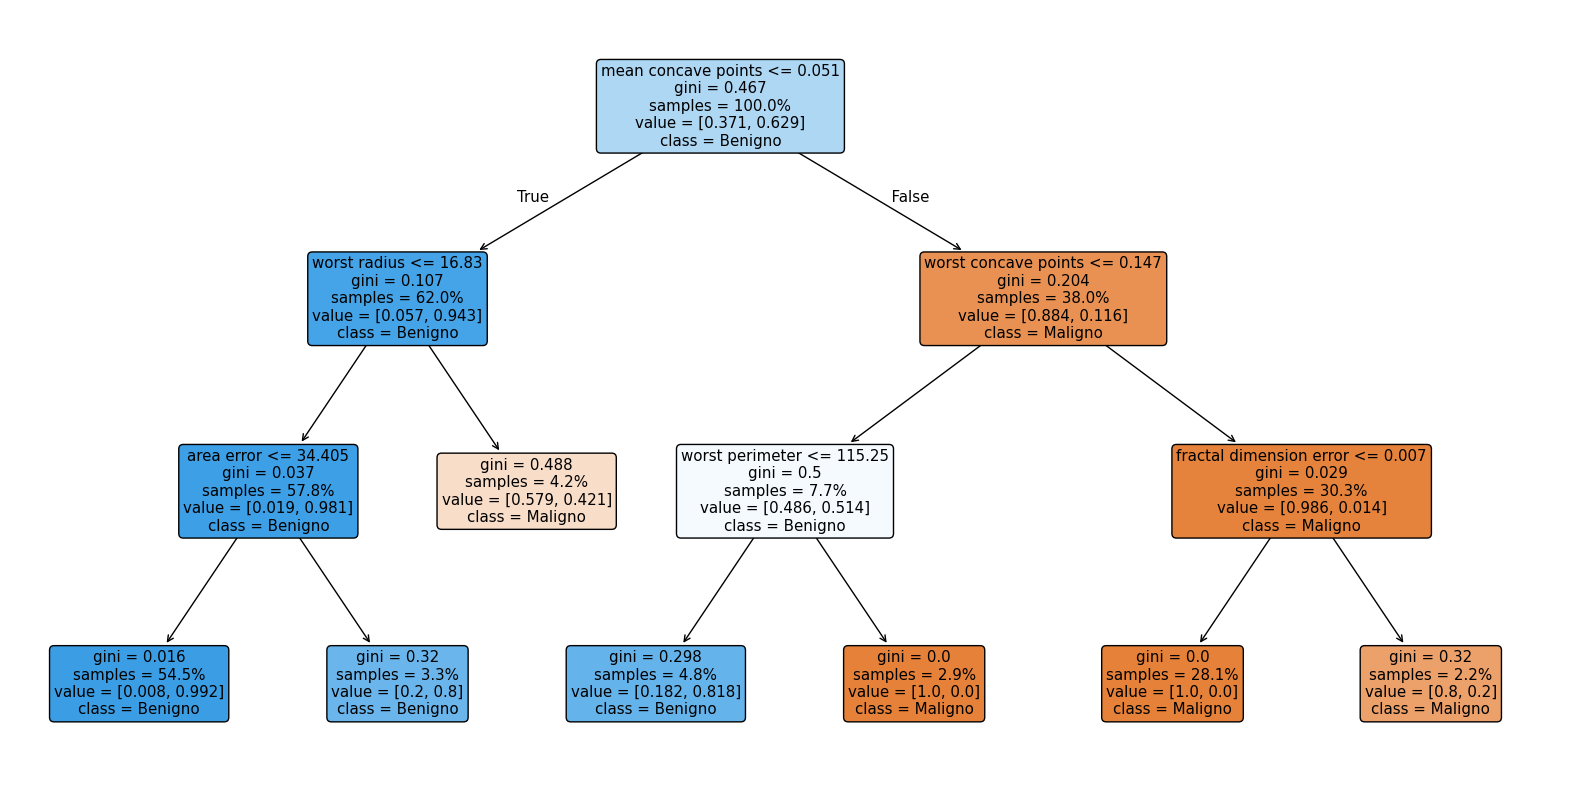

In [16]:
# Opción 2: Visualización Gráfica
plt.figure(figsize=(20,10))
plot_tree(
    model,
    feature_names=data.feature_names,
    class_names=['Maligno', 'Benigno'],
    filled=True,
    rounded=True,
    proportion=True
)
plt.show()

4. Interpretación de las Reglas del Modelo
Ejemplo de interpretación:
Si el output muestra:

|--- worst radius <= 16.80
|   |--- worst concave points <= 0.05
|   |   |--- mean texture <= 21.35
|   |   |   |--- class: Benigno
|   |   |--- mean texture >  21.35
|   |   |   |--- class: Maligno
Puedes interpretarlo como:

* Primera división: Tumores con radio ≤ 16.8 tienen diferente comportamiento

* Para estos tumores, si los puntos cóncavos ≤ 0.05 y textura ≤ 21.35 → Benigno

* Misma condición pero textura > 21.35 → Maligno

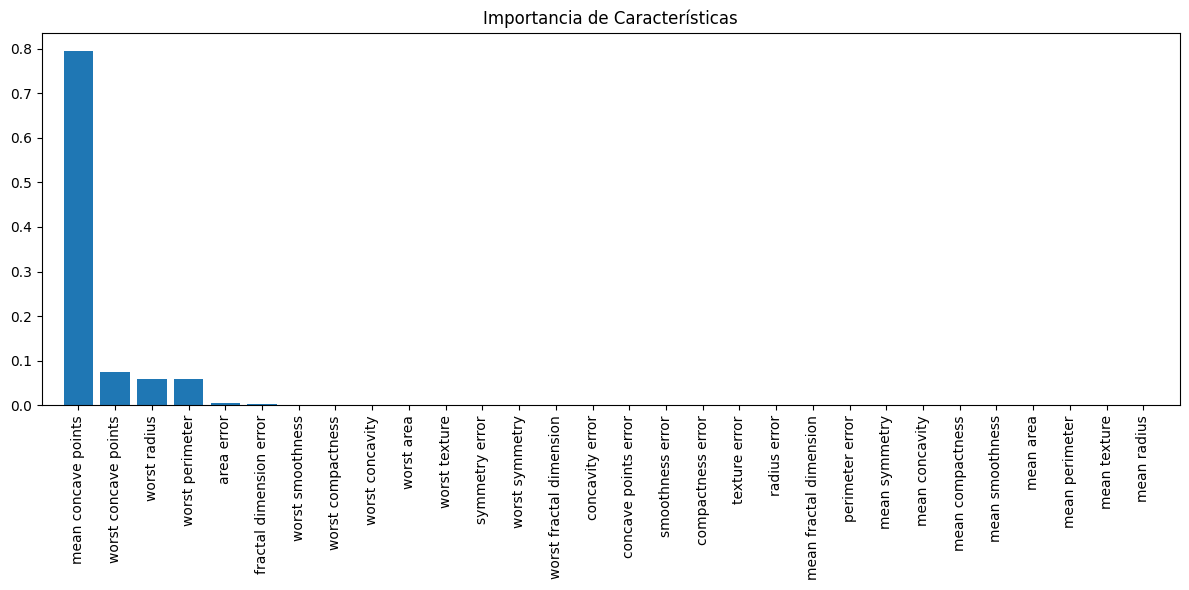


Ruta de decisión para la muestra:
Nodo 0: mean concave points (<= 0.05)
Nodo 6: worst concave points (<= 0.15)
Nodo 10: fractal dimension error (<= 0.01)


In [12]:
# 5. Importancia de Características Intrínseca
# Obtener importancia de características
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

# Visualizar
plt.figure(figsize=(12,6))
plt.title("Importancia de Características")
plt.bar(range(X_train.shape[1]), importances[indices], align="center")
plt.xticks(range(X_train.shape[1]), data.feature_names[indices], rotation=90)
plt.xlim([-1, X_train.shape[1]])
plt.tight_layout()
plt.show()

In [13]:
# 6. Análisis de Predicciones Individuales
# Analizar una predicción específica
sample_idx = 5
sample = X_test.iloc[[sample_idx]]

# Obtener ruta de decisión
leaf_id = model.apply(sample)[0]
node_indicator = model.decision_path(sample)

# Obtener hojas
leaf_id = model.apply(sample)
feature = model.tree_.feature
threshold = model.tree_.threshold

print("\nRuta de decisión para la muestra:")
node_index = node_indicator.indices[node_indicator.indptr[0]:
                                    node_indicator.indptr[1]]
for node_id in node_index:
    if leaf_id[0] == node_id:
        continue
    print(
        f"Nodo {node_id}: {data.feature_names[feature[node_id]]} "
        f"(<= {threshold[node_id]:.2f})"
    )


Ruta de decisión para la muestra:
Nodo 0: mean concave points (<= 0.05)
Nodo 6: worst concave points (<= 0.15)
Nodo 10: fractal dimension error (<= 0.01)


7. Ventajas de este Enfoque

* Transparencia total: Puedes seguir exactamente cómo se toma cada decisión

* Explicaciones exactas: No son aproximaciones como en LIME/SHAP

* Sin caja negra: Todo el proceso de decisión es visible

8. Limitaciones y Consideraciones

* Profundidad del árbol: Árboles muy profundos pierden interpretabilidad

* Variables continuas: Las divisiones pueden ser menos intuitivas

* Interacciones complejas: Difíciles de representar completamente